# 08 · What privacy costs (E3)

**Step E3 of the project plan: what privacy costs** (rule R10, and the opt-in question of rule R1). The recommender learns from statistics about
*other* members: how big each group is, and how many members each pair of groups shares. Those numbers can give people away ("only one other
person is in both *Anxiety support* and *Finals countdown*: it must be her"). Rule R10 protects them with **differential privacy**: each member
counts for at most *m* groups, and the counts get random noise, just enough that nobody can tell from the suggestions whether any one member is in
the data. The amount of protection is set by **ε (epsilon)**: smaller ε means more noise, more privacy, and less accurate suggestions.
This notebook measures that price, so that we can choose ε and *m* and defend the choice in the report.

What it does:

1. lists which statistics need protecting, and which do not;
2. explains the noise (the maths in one cell);
3. measures accuracy (NDCG@5) and the share of slots for new or small groups at ε ∈ {0.1, 0.5, 1, 2, 5, ∞} and *m* ∈ {3, 5, 8}, with several noise
   draws each: first on the practice quiz, to **choose** ε and *m* with a rule stated in advance, then on the test, to **report** them (the
   privacy-utility curve);
4. compares **opt-in with everyone** (R1): what if only the members who switched personalisation on fed the statistics?
5. checks whether the reasons still tell the truth when the counts they quote are noisy (R6);
6. says plainly what the guarantee does not cover.

Run notebooks 01, 02 and 06 first (this one reads `results/e1_methods.csv`). The code shared by all notebooks is in `boingrec.py`, in this folder;
the privacy code is its section 10. The whole notebook takes 30 to 60 minutes (about 730 runs of the recommender).

## 0 · Settings and data

In [1]:
# Colab only: upload sim_v1.zip and sim_v1_split.zip (from notebooks 01 and 02) and boingrec.py (from the notebooks folder),
# all three at once. Locally this cell does nothing.
import sys, zipfile
from pathlib import Path
if 'google.colab' in sys.modules and not Path('boingrec.py').exists():
    from google.colab import files
    for fname in files.upload():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(fname) as z:
                z.extractall('data')

In [2]:
import json
import math
import time
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import boingrec as br

SEED, K = br.SEED, br.K              # 0 and 5, the same in every notebook
EPSILONS = [0.1, 0.5, 1, 2, 5, math.inf]   # privacy budgets to try (interim report, Table 3); inf = no noise
MS = [3, 5, 8]                       # the most groups one member may count for
SHARES = [0.1, 0.25, 0.5]            # share of the budget spent on the group sizes (the rest goes to the pair counts)
QUIZ_DRAWS = range(5)                # noise draws per setting on the practice quiz (to choose)
TEST_DRAWS = range(10)               # noise draws per setting on the test (to report)
OPT_IN = [0.25, 0.5, 1.0]            # shares of members who switch personalisation on (section 8)
KEEP = 0.9                           # the rule of section 5: privacy may cost at most 10% (see there)
COLS = ['hit_rate', 'ndcg@5', 'newcomer_share', 'gini', 'coverage']
br.use_style()
cfg = br.Config()                    # the proposed design (notebook 06), with no privacy: eps = None, m = None

vis = br.load_visible()              # what a recommender may read: no test file, no hidden column
ans = br.load_answers()              # the answer key: only the scoring code reads it
tested = sorted(ans.test.user_id.unique())
fit, val = br.val_split(vis)         # the practice quiz (as in notebooks 04 to 06)
quiz_users = sorted(val.user_id.unique())
gids = br.group_ids(vis)
name = vis.groups.set_index('group_id').name
# The public topic clusters (R5) come from the groups' public texts only, the same for the quiz and the test:
# computed once and handed to recommend(), which saves time on each of the ~700 runs
CLUSTERS = br.topic_clusters(vis)
print(f'{len(vis.train)} visible memberships; test: {len(ans.test)} hidden memberships of {len(tested)} users; '
      f'practice quiz: {len(val)} of {len(quiz_users)} users')

6428 visible memberships; test: 1531 hidden memberships of 1406 users; practice quiz: 1093 of 1090 users


## 1 · What needs protecting, and what does not

Only the statistics that describe **other members** need noise. The rest is the member's own data, or public.

| What the recommender uses | Whose data | Protected by noise? |
|---|---|---|
| The member's own groups, and those they marked "not interested" | their own, used only for them | not needed |
| Group names and descriptions; the topics a member chose to share | public, or their own | not needed |
| **Group sizes**: which groups are "small" for the newcomer quota (R4), and the overlaps of "also joined" | other members | **yes** |
| **How many members each pair of groups shares** (X<sup>T</sup>X): "also joined" and the AI model | other members | **yes**: the AI model learns from the noisy table, so it is covered too |
| Friends in a group ("Your friend user 68 is a member") | other members | **no** (below) |
| Recent posts and likes (only the default list, personalisation off) | other members | not in this experiment (below) |

**The friends signal is not covered by the noise.** "Your friend user 68 is a member" names a real person and must be true (R6): noise would make it
false, and a count of one friend cannot be hidden by noise anyway. So it is protected by choice instead of maths: only friends whose profile is
**public** count, never across a block, and only accounts that count (R8, R9). A public profile is the friend's own decision to be seen; a friend with a
private profile is never used, not even silently inside a score. What is left is real: a suggestion can tell a member which group a public friend is in.
If BOING's public profiles do not already list a member's groups, this reveals more than the profile does, and it should become an opt-in of its own.

**The recent activity gets no noise here.** The default list (personalisation off) ranks groups by recent posts and likes, which are also counts of other
members' actions. The personal suggestions measured here never use them. Protecting them takes the same recipe (cap each member's posts and likes per
month, add noise) with its own share of the budget. We leave that to the BOING version and say so in the report.

## 2 · The noise, in one cell of maths

- **The promise** (ε-differential privacy; Dwork & Roth, 2014). A random computation *M* is ε-differentially private if, for any two communities
  *D* and *D′* that differ by one member (with all their memberships) and any set *S* of possible results,
  $$P[M(D) \in S] \le e^{\varepsilon}\, P[M(D') \in S].$$
  In words: whatever the suggestions are, they were at most $e^{\varepsilon}$ times more likely with you in the data than without you
  ($e^{0.5} = 1.6$, $e^{1} = 2.7$, $e^{2} = 7.4$, $e^{5} = 148$).
- **Contribution clipping.** Each member counts for at most *m* groups (if they have more, a random *m* of theirs, drawn from a seeded hash of the
  member and the group, so one member's draw never depends on anyone else). Then adding or removing one member changes the group sizes by at most
  $\Delta_{\text{size}} = m$ in total (1 per group) and the pair counts $c_{ij}$ ($i<j$) by at most $\Delta_{\text{pair}} = m(m-1)/2$ (1 per pair of
  their groups). If the fake-account rule (R9, notebook 09) makes young accounts count less, each membership weighs at most 1 and the bounds still hold.
- **The Laplace mechanism.** Each size gets its own noise drawn from $\text{Laplace}(\Delta_{\text{size}}/\varepsilon_{\text{size}})$, each pair count
  from $\text{Laplace}(\Delta_{\text{pair}}/\varepsilon_{\text{pair}})$, with $\varepsilon_{\text{size}} = s\,\varepsilon$ and
  $\varepsilon_{\text{pair}} = (1-s)\,\varepsilon$ for a split *s* of the budget (chosen in section 5). The two releases together are
  $(\varepsilon_{\text{size}} + \varepsilon_{\text{pair}}) = \varepsilon$-private (basic composition). Laplace noise of scale *b* is off by *b* on average.
- **Post-processing keeps the promise.** Negative counts become 0, a pair never shares more members than its smaller group has, and the table is
  mirrored. Everything after that (the overlaps of "also joined", the AI model's tastes, which groups count as small, the re-ranking, the reasons)
  reads only the noisy table, so it is ε-private too.

The table below shows what clipping removes in this community, and how far one member can move the counts.

In [3]:
counted = vis.users.user_id[vis.users.suspended == 0]                 # suspended accounts never count (R8)
per_member = vis.train[vis.train.user_id.isin(counted)].groupby('user_id').size()
clip_table = pd.DataFrame({f'm = {m}': {
    'members with more than m groups': int((per_member > m).sum()),
    'share of memberships kept': np.minimum(per_member, m).sum() / per_member.sum(),
    'one member moves the sizes by at most': br.dp_sensitivity(m)[0],
    'one member moves the pair counts by at most': br.dp_sensitivity(m)[1]} for m in MS}).T
print(f'In the training data, members have 1 to {per_member.max()} groups (median {per_member.median():.0f}).')
clip_table.round(3)

In the training data, members have 1 to 8 groups (median 3).


,members with more than m groups,share of memberships kept,one member moves the sizes by at most,one member moves the pair counts by at most
m = 3,775.0,0.744,3.0,3.0
m = 5,309.0,0.950,5.0,10.0
m = 8,0.0,1.000,8.0,28.0


With *m* = 8 nobody is clipped (no one has more than 8 groups here), but one member can move the pair counts by up to 28, so the noise must be
large. With *m* = 3 about a quarter of the memberships are left out of the statistics, but the noise can be much smaller. The experiment finds the
balance. (A member's own groups are never clipped: their suggestions still start from all of them.)

## 3 · Three reference points

- **No privacy**: the proposed design of notebook 06 (no clipping, no noise). The top of the curve.
- **No statistics about others**: the same design with the two parts that need statistics ("also joined" and the AI model) switched off, so it ranks
  only by friends and similar descriptions; its newcomer quota can only use *new* groups (created in the last 30 days, which is public), since
  "small" needs the group sizes. It reveals nothing through statistics: the floor that noisy statistics must beat to be worth using.
- **Popularity**: today's BOING (biggest groups first).

In [4]:
NO_STATS = replace(cfg, alpha=0.0, delta=0.0)        # friends (0.3) and similar descriptions (0.1) only

def no_stats(v):
    # Statistics for the design that uses none about other members: the tables are zeroed (so nothing can leak
    # through them), and only public "new" groups count as newcomers for the quota
    s = br.stats_for(v, cfg)
    created = v.groups.set_index('group_id').created_day
    new = set(created.index[created > br.TODAY - br.NEW_DAYS]) & set(s.gids.tolist())
    return replace(s, co=s.co * 0.0, jaccard=s.jaccard * 0.0, sizes=s.sizes * 0.0, tastes=s.tastes * 0.0,
                   taste_strength=s.taste_strength * 0.0, newcomers=new)

def run(users, v, truth, config, stats=None, allowed=None, per_user=False):
    # One run of the proposed design: the statistics (clipped and noisy as `config` says) -> recommend() -> scores.
    # Returns the evaluate() row (plus 'valid': every list has 5 different allowed groups) and, if per_user, each user's NDCG@5.
    stats = stats if stats is not None else br.stats_for(v, config)
    lists = br.lists_from(br.recommend(users, v, config, stats, clusters=CLUSTERS))
    row = br.evaluate(lists, truth, v)
    if allowed is not None:
        row['valid'] = all(len(set(lists[u])) == K == len(lists[u]) and allowed.loc[u, lists[u]].all() for u in users)
    return row, (br.relevance_per_user(lists, truth)['ndcg@5'] if per_user else None)

refs, ref_users = {}, {}
for where, (users, v, truth) in {'quiz': (quiz_users, fit, val), 'test': (tested, vis, ans.test)}.items():
    refs[(where, 'no privacy')], ref_users[(where, 'no privacy')] = run(users, v, truth, cfg, per_user=True)
    refs[(where, 'no statistics')], _ = run(users, v, truth, NO_STATS, stats=no_stats(v))
    pop = br.top_k(br.popularity_scores(v, users), v)
    refs[(where, 'popularity')] = br.evaluate(pop, truth, v)
reference = pd.DataFrame({f'{d} ({w})': r[COLS] for (w, d), r in refs.items()}).T
reference.round(3)

,hit_rate,ndcg@5,newcomer_share,gini,coverage
no privacy (quiz),0.611,0.465,0.202,0.530,122.0
no statistics (quiz),0.489,0.377,0.243,0.520,126.0
popularity (quiz),0.211,0.122,0.000,0.955,10.0
no privacy (test),0.656,0.528,0.203,0.511,125.0
no statistics (test),0.542,0.424,0.241,0.517,127.0
popularity (test),0.220,0.131,0.000,0.953,10.0


## 4 · The sweep on the practice quiz (to choose)

For every split *s* of the budget, every ε and every *m*: 5 noise draws (`noise_seed` 0 to 4; with ε = ∞ there is no noise and the draws only change
which groups are clipped). Each draw rebuilds the statistics with `br.stats_for(fit, config)` and serves all the quiz users together with
`br.recommend()`. The runs are split over three cells, so that each one shows its progress.

In [5]:
FINITE = [e for e in EPSILONS if not math.isinf(e)]

def sweep(users, v, truth, share, epsilons, draws, keep=None):
    # One run per (eps, m, draw), with `share` of the budget on the sizes (share None for eps = inf: no noise, no split).
    # keep = (eps, m): the setting whose per-user NDCG@5 is kept (for the paired 95% range of section 6).
    allowed = br.candidate_mask(v, users)
    rows, users_ndcg = [], {}
    for eps in epsilons:
        for m in MS:
            for d in draws:
                c = replace(cfg, eps=eps, m=m, noise_seed=d, **({} if share is None else {'size_share': share}))
                row, pu = run(users, v, truth, c, allowed=allowed, per_user=(eps, m) == keep)
                rows.append({'size_share': np.nan if share is None else share, 'eps': eps, 'm': m, 'draw': d,
                             **row[COLS + ['valid']].to_dict()})
                if pu is not None:
                    users_ndcg[d] = pu
    return pd.DataFrame(rows), users_ndcg

def summarise(runs, ref):
    # Mean and spread (standard deviation) over the draws, and how much of the no-privacy design each setting keeps
    g = runs.groupby(['size_share', 'eps', 'm'], dropna=False, sort=True)
    out = g[COLS].mean()
    for col in ['ndcg@5', 'newcomer_share']:
        out[f'{col} sd'] = g[col].std(ddof=1)
    out['runs'] = g.size()
    out['accuracy kept'] = out['ndcg@5'] / ref['ndcg@5']
    out['newcomer slots kept'] = out['newcomer_share'] / ref['newcomer_share']
    return out.reset_index()

def grid(summary, col):
    # One row per split and m, one column per eps; eps = inf has no noise, so its value is the same for every split
    fin = summary[np.isfinite(summary.eps)].pivot_table(index=['size_share', 'm'], columns='eps', values=col)
    no_noise = summary[np.isinf(summary.eps)].set_index('m')[col]
    fin['inf (no noise)'] = [no_noise[m] for _, m in fin.index]
    return fin

start = time.time()
quiz_parts = {'no noise': sweep(quiz_users, fit, val, None, [math.inf], QUIZ_DRAWS),
              SHARES[0]: sweep(quiz_users, fit, val, SHARES[0], FINITE, QUIZ_DRAWS)}
print(f'{sum(len(r) for r, _ in quiz_parts.values())} runs in {(time.time() - start) / 60:.1f} minutes')

90 runs in 1.6 minutes


In [6]:
start = time.time()
quiz_parts[SHARES[1]] = sweep(quiz_users, fit, val, SHARES[1], FINITE, QUIZ_DRAWS)
print(f'{len(quiz_parts[SHARES[1]][0])} runs in {(time.time() - start) / 60:.1f} minutes')

75 runs in 1.3 minutes


In [7]:
start = time.time()
quiz_parts[SHARES[2]] = sweep(quiz_users, fit, val, SHARES[2], FINITE, QUIZ_DRAWS)
print(f'{len(quiz_parts[SHARES[2]][0])} runs in {(time.time() - start) / 60:.1f} minutes')
quiz_runs = pd.concat([r for r, _ in quiz_parts.values()], ignore_index=True)
quiz = summarise(quiz_runs, refs[('quiz', 'no privacy')])
grid(quiz, 'ndcg@5').round(3)

75 runs in 1.4 minutes


eps             0.1    0.5    1.0    2.0    5.0  inf (no noise)
size_share m                                                   
0.10       3  0.229  0.334  0.402  0.433  0.452           0.459
           5  0.210  0.271  0.342  0.407  0.448           0.464
           8  0.192  0.211  0.247  0.315  0.396           0.465
0.25       3  0.209  0.333  0.384  0.423  0.449           0.459
           5  0.188  0.267  0.333  0.391  0.441           0.464
           8  0.167  0.205  0.245  0.306  0.383           0.465
0.50       3  0.197  0.294  0.351  0.396  0.441           0.459
           5  0.187  0.247  0.301  0.362  0.421           0.464
           8  0.173  0.215  0.242  0.275  0.352           0.465

Accuracy (NDCG@5) on the practice quiz, averaged over the draws: one row per split and *m*, one column per ε.
The share of slots for new or small groups, the other value at stake:

In [8]:
grid(quiz, 'newcomer_share').round(3)

eps             0.1    0.5    1.0    2.0    5.0  inf (no noise)
size_share m                                                   
0.10       3  0.241  0.211  0.199  0.162  0.141           0.161
           5  0.281  0.251  0.234  0.219  0.162           0.202
           8  0.303  0.273  0.243  0.247  0.220           0.202
0.25       3  0.261  0.243  0.218  0.193  0.188           0.161
           5  0.318  0.253  0.236  0.214  0.195           0.202
           8  0.320  0.274  0.245  0.229  0.213           0.202
0.50       3  0.278  0.232  0.207  0.197  0.207           0.161
           5  0.293  0.216  0.204  0.198  0.202           0.202
           8  0.309  0.227  0.193  0.186  0.192           0.202

## 5 · Choosing ε and *m*: the rule

The rule, fixed before looking at the test:

> Take the **strongest privacy** (the smallest ε) at which some setting keeps **at least 90% of the accuracy** (NDCG@5) **and at least 90% of the
> newcomer slots** of the design without privacy, on the practice quiz. Among the settings that pass at that ε, take the most accurate (its *m* and split).

Why these two conditions: privacy is a value we are willing to pay for, but not with most of the benefit; and the noise must not quietly undo the
fairness rule R4 (noisy sizes can make the quota go to groups that only *look* small). 90% is our judgement, the same bar for both; the Discussion defends it.

In [9]:
ref_quiz = refs[('quiz', 'no privacy')]
quiz['passes'] = (quiz['accuracy kept'] >= KEEP) & (quiz['newcomer slots kept'] >= KEEP) & np.isfinite(quiz['eps'])
passing = quiz[quiz.passes].sort_values(['eps', 'ndcg@5'], ascending=[True, False], kind='stable')
assert len(passing), 'no setting keeps 90% of both: the rule picks nothing'
best = passing.iloc[0]
EPS, M, SHARE = float(best.eps), int(best.m), float(best.size_share)
PRIVATE = replace(cfg, eps=EPS, m=M, size_share=SHARE)           # the recommended setting (noise_seed: one per draw)
print(f'Chosen: epsilon = {EPS:g}, m = {M}, {SHARE:.0%} of the budget on the sizes. On the practice quiz it keeps '
      f'{best["accuracy kept"]:.1%} of the accuracy (NDCG@5 {best["ndcg@5"]:.3f} vs {ref_quiz["ndcg@5"]:.3f}) and '
      f'{best["newcomer slots kept"]:.1%} of the newcomer slots ({best["newcomer_share"]:.1%} vs {ref_quiz["newcomer_share"]:.1%}).')
print(f'boingrec holds it: br.PRIVATE = {br.PRIVATE}, br.Config().size_share = {br.Config().size_share}')

# For each epsilon: the most accurate setting, and the most accurate one that passes both conditions
finite = quiz[np.isfinite(quiz['eps'])]
cols = ['size_share', 'm', 'ndcg@5', 'accuracy kept', 'newcomer_share', 'newcomer slots kept']
per_eps = pd.concat({
    'most accurate': finite.loc[finite.groupby('eps')['ndcg@5'].idxmax(), ['eps'] + cols].set_index('eps'),
    'most accurate that passes': passing.groupby('eps').head(1)[['eps'] + cols].set_index('eps')}, axis=1)
br.save_table(quiz, 'e3_privacy_validation.csv', decimals=4)
per_eps.round(3)

Chosen: epsilon = 2, m = 3, 25% of the budget on the sizes. On the practice quiz it keeps 90.9% of the accuracy (NDCG@5 0.423 vs 0.465) and 95.4% of the newcomer slots (19.3% vs 20.2%).
boingrec holds it: br.PRIVATE = {'eps': 2.0, 'm': 3, 'size_share': 0.25}, br.Config().size_share = 0.25


most accurate                                                             \
       size_share  m ndcg@5 accuracy kept newcomer_share newcomer slots kept   
eps                                                                            
0.1           0.1  3  0.229         0.493          0.241               1.196   
0.5           0.1  3  0.334         0.718          0.211               1.047   
1.0           0.1  3  0.402         0.865          0.199               0.985   
2.0           0.1  3  0.433         0.930          0.162               0.803   
5.0           0.1  3  0.452         0.971          0.141               0.697   

    most accurate that passes                                           \
                   size_share    m ndcg@5 accuracy kept newcomer_share   
eps                                                                      
0.1                       NaN  NaN    NaN           NaN            NaN   
0.5                       NaN  NaN    NaN           NaN            NaN   
1.0                       NaN  NaN    NaN           NaN            NaN   
2.0                      0.25  3.0  0.423         0.909          0.193   
5.0                      0.25  3.0  0.449         0.966          0.188   

                         
    newcomer slots kept  
eps                      
0.1                 NaN  
0.5                 NaN  
1.0                 NaN  
2.0               0.954  
5.0               0.930

### What the noise looks like at the chosen setting

The noise scales (Laplace *b*: the average error of each count), a few Discover groups' sizes as the recommender now sees them (one draw), and how
often the noisy sizes still tell "small" (fewer than 10 members) apart correctly.

In [10]:
scale_size, scale_pair = br.dp_scales(EPS, M, SHARE)
true_stats = br.stats_for(vis, cfg)
clip_stats = br.stats_for(vis, replace(PRIVATE, eps=math.inf, noise_seed=0))
noisy_stats = br.stats_for(vis, replace(PRIVATE, noise_seed=0))
co_true = true_stats.co.to_numpy()[np.triu_indices(len(gids), k=1)]
print(f'epsilon = {EPS:g}, m = {M}: each size is off by {scale_size:.1f} members on average, each pair count by {scale_pair:.1f}. '
      f'For scale: the median group has {np.median(true_stats.sizes):.0f} members, and the pairs of groups that share members '
      f'share {np.median(co_true[co_true > 0]):.0f} (median).')
discover = br.discover_groups(vis.groups)
by_size = true_stats.sizes[discover].sort_values(ascending=False, kind='stable')
example = by_size.index[np.linspace(0, len(by_size) - 1, 7).round().astype(int)].tolist()   # big to small
truly_new_or_small = br.newcomer_groups(vis)
display(pd.DataFrame({'group': name[example], 'members': true_stats.sizes[example].astype(int),
                      f'counted (m = {M})': clip_stats.sizes[example].astype(int),
                      'with noise (draw 0)': noisy_stats.sizes[example].round(1),
                      'new or small? true': [g in truly_new_or_small for g in example],
                      'as the recommender sees it': [g in noisy_stats.newcomers for g in example]},
                     index=pd.Index(example, name='group_id')))

# How well the noisy sizes find the new or small groups, over the 10 draws (Discover groups only)
seen = []
for d in TEST_DRAWS:
    s = br.stats_for(vis, replace(PRIVATE, noise_seed=d))
    looks = {g for g in discover if g in s.newcomers}
    truth_ = {g for g in discover if g in truly_new_or_small}
    seen.append({'draw': d, 'truly new or small': len(truth_), 'look new or small': len(looks),
                 'found (of the true ones)': len(looks & truth_) / len(truth_),
                 'right (of those that look it)': len(looks & truth_) / max(len(looks), 1)})
seen = pd.DataFrame(seen).set_index('draw')
seen.mean().round(3)

epsilon = 2, m = 3: each size is off by 6.0 members on average, each pair count by 2.0. For scale: the median group has 13 members, and the pairs of groups that share members share 2 (median).


,group,members,counted (m = 3),with noise (draw 0),new or small? true,as the recommender sees it
group_id,,,,,,
10,Weightlifting for beginners,291,218,230.2,False,False
43,SQL from zero,108,78,79.3,False,False
38,Curious about Astronomy,43,26,35.1,False,False
92,Thermodynamics explained,17,15,31.5,False,False
90,Calisthenics for beginners,6,4,7.7,True,True
141,Finals prep squad,2,0,0.7,True,True
148,Mastering Linear algebra,0,0,6.2,True,True


truly new or small               53.000
look new or small                57.400
found (of the true ones)          0.909
right (of those that look it)     0.841
dtype: float64

## 6 · The test (to report): the privacy-utility curve

The chosen split for every point, every ε and *m*, 10 noise draws each, on the 1,406 tested users.

In [11]:
start = time.time()
test_parts = {'no noise': sweep(tested, vis, ans.test, None, [math.inf], TEST_DRAWS),
              'strongest': sweep(tested, vis, ans.test, SHARE, [0.1, 0.5], TEST_DRAWS, keep=(EPS, M))}
print(f'{sum(len(r) for r, _ in test_parts.values())} runs in {(time.time() - start) / 60:.1f} minutes')

90 runs in 2.4 minutes


In [12]:
start = time.time()
test_parts['middle'] = sweep(tested, vis, ans.test, SHARE, [1, 2], TEST_DRAWS, keep=(EPS, M))
print(f'{len(test_parts["middle"][0])} runs in {(time.time() - start) / 60:.1f} minutes')

60 runs in 1.6 minutes


In [13]:
start = time.time()
test_parts['weakest'] = sweep(tested, vis, ans.test, SHARE, [5], TEST_DRAWS, keep=(EPS, M))
print(f'{len(test_parts["weakest"][0])} runs in {(time.time() - start) / 60:.1f} minutes')
test_runs = pd.concat([r for r, _ in test_parts.values()], ignore_index=True)
chosen_users = {d: pu for _, part in test_parts.values() for d, pu in part.items()}   # the chosen setting, per draw
ref_test = refs[('test', 'no privacy')]
test = summarise(test_runs, ref_test)

# results/e3_privacy.csv: every (eps, m) on the test, then the three reference points
extra = []
for key, label_ in [('no privacy', 'no privacy (proposed design)'), ('no statistics', 'no statistics about others'),
                    ('popularity', 'popularity (today)')]:
    r = refs[('test', key)]
    extra.append({'design': label_, 'eps': math.inf if key == 'no privacy' else np.nan, 'runs': 1, **r[COLS].to_dict(),
                  'accuracy kept': r['ndcg@5'] / ref_test['ndcg@5'],
                  'newcomer slots kept': r['newcomer_share'] / ref_test['newcomer_share']})
design = np.where(np.isinf(test.eps), 'clipping only (no noise)', 'with privacy noise')
table = pd.concat([test.assign(design=design), pd.DataFrame(extra)], ignore_index=True)
table = table[['design', 'eps', 'm', 'size_share', 'runs'] + COLS + ['ndcg@5 sd', 'newcomer_share sd',
                                                                    'accuracy kept', 'newcomer slots kept']]
br.save_table(table.set_index('design'), 'e3_privacy.csv', decimals=4)
pd.concat([quiz_runs.assign(where='practice quiz'), test_runs.assign(where='test')]).to_csv(br.RESULTS / 'e3_privacy_runs.csv', index=False)
test.pivot_table(index='m', columns='eps', values='ndcg@5').round(3)

30 runs in 0.8 minutes


eps,0.1,0.5,1.0,2.0,5.0,inf
m,,,,,,
3,0.260,0.408,0.461,0.495,0.516,0.526
5,0.238,0.362,0.434,0.482,0.516,0.530
8,0.217,0.287,0.351,0.419,0.485,0.528


Newcomer share on the test (share of slots for new or small groups, by the true sizes):

In [14]:
test.pivot_table(index='m', columns='eps', values='newcomer_share').round(3)

eps,0.1,0.5,1.0,2.0,5.0,inf
m,,,,,,
3,0.237,0.219,0.199,0.178,0.160,0.132
5,0.262,0.225,0.218,0.202,0.193,0.192
8,0.291,0.244,0.227,0.213,0.201,0.203


**What privacy costs at the chosen setting**, per user against the design without privacy (each user's NDCG@5 averaged over the 10 draws;
a paired 95% range from resampling the users, as for the price of fairness in notebook 06):

In [15]:
private_users = pd.concat([chosen_users[d] for d in TEST_DRAWS], axis=1).mean(axis=1)
cost = ref_users[('test', 'no privacy')] - private_users
cost_low, cost_high = br.bootstrap_ci(cost)
chosen_test = test[(test.eps == EPS) & (test.m == M)].iloc[0]
print(f'epsilon = {EPS:g}, m = {M} on the test: NDCG@5 {chosen_test["ndcg@5"]:.3f} (sd {chosen_test["ndcg@5 sd"]:.3f} over {len(TEST_DRAWS)} draws), '
      f'against {ref_test["ndcg@5"]:.3f} without privacy: it costs {cost.mean():.3f} (95% range {cost_low:.3f} to {cost_high:.3f}), '
      f'{cost.mean() / ref_test["ndcg@5"]:.1%} of the accuracy.')
print(f'Newcomer share {chosen_test["newcomer_share"]:.1%} (without privacy {ref_test["newcomer_share"]:.1%}). '
      f'No statistics at all: NDCG@5 {refs[("test", "no statistics")]["ndcg@5"]:.3f}; popularity: {refs[("test", "popularity")]["ndcg@5"]:.3f}.')

epsilon = 2, m = 3 on the test: NDCG@5 0.495 (sd 0.003 over 10 draws), against 0.528 without privacy: it costs 0.033 (95% range 0.025 to 0.041), 6.2% of the accuracy.
Newcomer share 17.8% (without privacy 20.3%). No statistics at all: NDCG@5 0.424; popularity: 0.131.


## 7 · The chart

Accuracy and the share of slots for new or small groups against ε (log scale; ∞ = no noise, clipping only), one line per *m*; the band is ± 1 standard
deviation over the 10 noise draws. The violet is the "With privacy noise" colour of every figure, in three steps for the three caps *m*.

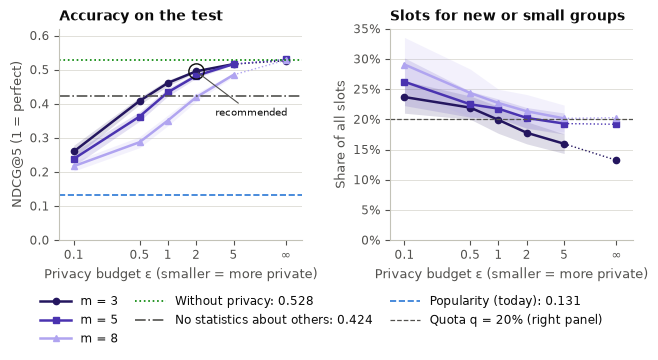

In [16]:
INF_X = 18                                          # where eps = inf sits on the log axis
x_of = lambda e: INF_X if math.isinf(e) else e
markers = {3: 'o', 5: 's', 8: '^'}
fig, axes = plt.subplots(1, 2, figsize=(br.WIDTH, 3.6))
panels = [('ndcg@5', 'Accuracy on the test', 'NDCG@5 (1 = perfect)'),
          ('newcomer_share', 'Slots for new or small groups', 'Share of all slots')]
for ax, (col, title, ylabel) in zip(axes, panels):
    for m in MS:
        rows = test[test.m == m].sort_values('eps')
        x = np.array([x_of(e) for e in rows.eps])
        y, sd = rows[col].to_numpy(), rows[f'{col} sd'].fillna(0).to_numpy()
        colour = br.PRIVACY_M_COLOURS[m]
        ax.fill_between(x[:-1], (y - sd)[:-1], (y + sd)[:-1], color=colour, alpha=0.15, linewidth=0)
        ax.plot(x[:-1], y[:-1], color=colour, marker=markers[m], markersize=4.5, linewidth=1.8, label=f'm = {m}')
        ax.plot(x[-2:], y[-2:], color=colour, linewidth=1.0, linestyle=':')            # the jump to "no noise"
        ax.plot(x[-1], y[-1], color=colour, marker=markers[m], markersize=4.5, linestyle='none')
    ax.set_xscale('log')
    ax.set_xticks([x_of(e) for e in EPSILONS], ['0.1', '0.5', '1', '2', '5', '∞'])
    ax.minorticks_off()
    ax.set_xlim(0.07, INF_X * 1.5)
    ax.set_xlabel('Privacy budget ε (smaller = more private)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.yaxis.grid(True)

# The reference lines are named in the shared legend below the panels (with their values), not on the plot,
# where their labels would cross the curves
ax = axes[0]
for key, colour_, style, text in [('no privacy', br.colour('reranked'), ':', 'Without privacy'),
                                  ('no statistics', br.MUTED, '-.', 'No statistics about others'),
                                  ('popularity', br.colour('popularity'), '--', 'Popularity (today)')]:
    v = refs[('test', key)]['ndcg@5']
    ax.axhline(v, color=colour_, linestyle=style, linewidth=1.2, label=f'{text}: {v:.3f}')
ax.set_ylim(0, 0.62)
ax.plot(EPS, chosen_test['ndcg@5'], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=br.INK, markeredgewidth=1.0)
ax.annotate('recommended', (EPS, chosen_test['ndcg@5']), xytext=(EPS * 1.6, chosen_test['ndcg@5'] - 0.13), fontsize=7.5,
            color=br.INK, arrowprops=dict(arrowstyle='-', color=br.MUTED, linewidth=0.8))

ax = axes[1]
ax.axhline(cfg.q, color=br.MUTED, linestyle='--', linewidth=0.9, label=f'Quota q = {cfg.q:.0%} (right panel)')
ax.set_ylim(0, 0.35)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))

handles, labels = axes[0].get_legend_handles_labels()
h_q, l_q = axes[1].get_legend_handles_labels()
fig.legend(handles + h_q[-1:], labels + l_q[-1:], loc='lower center', ncol=3, handlelength=2.6, columnspacing=1.4,
           bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(w_pad=2.5, rect=(0, 0.17, 1, 1))
br.save_fig(fig, 'e3_privacy.png')
plt.show()

## 8 · Opt-in or everyone? (R1)

Personalisation is off until a member switches it on (R1). Should the members who did **not** switch it on still feed the statistics that others'
suggestions learn from? Two policies:

- **everyone counts**: all members' memberships feed the (noisy) statistics; R10 protects those who did not opt in;
- **only opted-in members count**: the statistics, the friends signal and the recent activity use only the members who switched personalisation on.

We draw who opts in at random (seeded, 10 draws; for each draw the 25% are inside the 50%), at 25%, 50% and 100%, without privacy and at the chosen
ε and *m*. Members who opted in get personal suggestions; the others get the default list (personalisation off), built from the same statistics.
We report the accuracy of the members who opted in, and of all tested members together.

In [17]:
def opted_in(share, draw):
    # A seeded random share of all members (seeds 1000 to 1009: a different stream from the noise draws)
    u = np.random.default_rng(1000 + draw).random(len(vis.users))
    return set(vis.users.user_id[u < share].tolist())

def opt_in_runs(setting, conf):
    # For each opt-in share and draw: both policies; opted-in members get personal suggestions, the others the default list
    rows = []
    for share in OPT_IN:
        for d in TEST_DRAWS:
            c = replace(conf, noise_seed=d) if conf.eps is not None else conf
            opted = opted_in(share, d)
            users_in = [u for u in tested if u in opted]
            users_out = [u for u in tested if u not in opted]
            policies = {'everyone counts': br.stats_for(vis, c),
                        'only opted-in members count': br.group_stats(vis.train, vis.users[vis.users.user_id.isin(opted)], c,
                                                                      groups=vis.groups, posts=vis.posts, likes=vis.likes)}
            for policy, stats in policies.items():
                lists_in = br.lists_from(br.recommend(users_in, vis, c, stats, clusters=CLUSTERS))
                lists_out = (br.lists_from(br.recommend(users_out, vis, replace(c, personal=False), stats, clusters=CLUSTERS))
                             if users_out else {})
                r_in = br.evaluate(lists_in, ans.test[ans.test.user_id.isin(users_in)], vis)
                everyone_ndcg = br.relevance_per_user({**lists_in, **lists_out}, ans.test)['ndcg@5'].mean()
                rows.append({'opt_in': share, 'privacy': setting, 'policy': policy, 'draw': d,
                             'tested members opted in': len(users_in), 'ndcg@5 (opted in)': r_in['ndcg@5'],
                             'newcomer_share (opted in)': r_in['newcomer_share'], 'ndcg@5 (all tested)': everyone_ndcg})
    return rows

PRIVATE_LABEL = f'epsilon = {EPS:g}, m = {M}'
settings = {'no privacy': cfg, PRIVATE_LABEL: PRIVATE}
start = time.time()
opt_rows = opt_in_runs('no privacy', cfg)
print(f'{len(opt_rows)} runs in {(time.time() - start) / 60:.1f} minutes')

60 runs in 1.1 minutes


In [18]:
start = time.time()
opt_rows += opt_in_runs(PRIVATE_LABEL, PRIVATE)
print(f'{len(opt_rows)} runs in all, the last ones in {(time.time() - start) / 60:.1f} minutes')
opt_runs = pd.DataFrame(opt_rows)
g = opt_runs.groupby(['opt_in', 'privacy', 'policy'], sort=False)
opt = g[['tested members opted in', 'ndcg@5 (opted in)', 'newcomer_share (opted in)', 'ndcg@5 (all tested)']].mean()
opt['ndcg@5 (opted in) sd'] = g['ndcg@5 (opted in)'].std(ddof=1)
opt['ndcg@5 (all tested) sd'] = g['ndcg@5 (all tested)'].std(ddof=1)
opt['runs'] = g.size()
br.save_table(opt, 'e3_opt_in.csv', decimals=4)
opt.round(3)

120 runs in all, the last ones in 1.1 minutes


tested members opted in  \
opt_in privacy            policy                                                 
0.25   no privacy         everyone counts                                351.8   
                          only opted-in members count                    351.8   
0.50   no privacy         everyone counts                                708.5   
                          only opted-in members count                    708.5   
1.00   no privacy         everyone counts                               1406.0   
                          only opted-in members count                   1406.0   
0.25   epsilon = 2, m = 3 everyone counts                                351.8   
                          only opted-in members count                    351.8   
0.50   epsilon = 2, m = 3 everyone counts                                708.5   
                          only opted-in members count                    708.5   
1.00   epsilon = 2, m = 3 everyone counts                               1406.0   
                          only opted-in members count                   1406.0   

                                                       ndcg@5 (opted in)  \
opt_in privacy            policy                                           
0.25   no privacy         everyone counts                          0.524   
                          only opted-in members count              0.475   
0.50   no privacy         everyone counts                          0.535   
                          only opted-in members count              0.509   
1.00   no privacy         everyone counts                          0.528   
                          only opted-in members count              0.528   
0.25   epsilon = 2, m = 3 everyone counts                          0.489   
                          only opted-in members count              0.283   
0.50   epsilon = 2, m = 3 everyone counts                          0.501   
                          only opted-in members count              0.412   
1.00   epsilon = 2, m = 3 everyone counts                          0.495   
                          only opted-in members count              0.495   

                                                       newcomer_share (opted in)  \
opt_in privacy            policy                                                   
0.25   no privacy         everyone counts                                  0.203   
                          only opted-in members count                      0.045   
0.50   no privacy         everyone counts                                  0.203   
                          only opted-in members count                      0.096   
1.00   no privacy         everyone counts                                  0.203   
                          only opted-in members count                      0.203   
0.25   epsilon = 2, m = 3 everyone counts                                  0.175   
                          only opted-in members count                      0.185   
0.50   epsilon = 2, m = 3 everyone counts                                  0.176   
                          only opted-in members count                      0.162   
1.00   epsilon = 2, m = 3 everyone counts                                  0.178   
                          only opted-in members count                      0.178   

                                                       ndcg@5 (all tested)  \
opt_in privacy            policy                                             
0.25   no privacy         everyone counts                            0.171   
                          only opted-in members count                0.149   
0.50   no privacy         everyone counts                            0.298   
                          only opted-in members count                0.284   
1.00   no privacy         everyone counts                            0.528   
                          only opted-in members count                0.528   
0.25   epsilon = 2, m = 3 everyone count

How to read it: "ndcg@5 (opted in)" is the accuracy that the members who switched personalisation on get; "all tested" averages them with the
members who did not (who get the default list, NDCG@5 about 0.06 in notebook 06). At 100% opt-in both policies are the same, by construction.

## 9 · One member's suggestions, with privacy on

User 1 again (as in notebook 06), served alone: without privacy, then at the chosen setting (draw 0). With privacy on, a "shared members" reason says
**"About"**, because the count it shows is clipped and noisy.

In [19]:
plain = br.recommend([1], vis, cfg, clusters=CLUSTERS)
private_one = br.recommend([1], vis, replace(PRIVATE, noise_seed=0), clusters=CLUSTERS)
pd.DataFrame({'no privacy': plain.group_id.map(name).to_numpy(), 'reason': plain.reason_text.to_numpy(),
              PRIVATE_LABEL: private_one.group_id.map(name).to_numpy(),
              'reason with privacy': private_one.reason_text.to_numpy()},
             index=pd.Index(plain['rank'].to_numpy(), name='rank'))

,no privacy,reason,"epsilon = 2, m = 3",reason with privacy
rank,,,,
1,SAT prep squad,85 members of Finals countdown are in it,SAT prep squad,About 47 members of Finals countdown are in it
2,30 days of Reading,46 members of Journaling streak are in it,MCAT countdown,About 22 members of Finals countdown are in it
3,MCAT countdown,49 members of Finals countdown are in it,Beat the IELTS,Your friend user 68 and 1 other friend are mem...
4,Beat the IELTS,Your friend user 68 and 1 other friend are mem...,30 days of Reading,About 22 members of Journaling streak are in it
5,GRE study hall,A small group: we show small groups so they ge...,GRE prep squad,A small group: we show small groups so they ge...


## 10 · Do the noisy reasons still tell the truth? (R6)

A "shared members" reason quotes a count: "About 22 members of *Journaling streak* are in it". With privacy on, that is the noisy count the
recommender learned from, so the reason is still faithful to the score (R6). But the noise can also **invent a link**: two groups that truly share
nobody get a small positive count, and when one of them is small, that count makes their overlap ("also joined") look large. A member would then
read "About 3 members of *X* are in it" when none is. We count how often this happens at the chosen setting, on the test (10 draws). The true counts
come from the full table (every counted member, no clipping, no noise); only this scoring code reads it.

One remedy keeps the guarantee, because it reads only the noisy table: a **floor**. Every pair count loses *t* × *b* (*b* = the pair noise scale,
the average error of a pair count) and stops at 0, so a pair must clearly beat the noise to count. It changes the design, so we try it on the
practice quiz (*t* = 0, 1, 2, 3; 5 draws each) and keep the strongest floor that still passes the rule of section 5 (90% of the accuracy and of
the newcomer slots of the design without privacy).

In [20]:
B = scale_pair                                       # the pair noise scale at the chosen setting (section 5)
FLOORS = [0, 1, 2, 3]

def floored(s, t, b):
    # The floor (post-processing of the noisy table, so the guarantee holds): each pair count loses t x b and stops at 0.
    # The sizes, and so the newcomers, stay as they are; "also joined" and the AI model are recomputed from the new table.
    co = s.co.to_numpy().copy()
    off = ~np.eye(len(co), dtype=bool)
    co[off] = np.maximum(co[off] - t * b, 0.0)
    sizes = np.diag(co)
    either = sizes[:, None] + sizes[None, :] - co
    jac = np.divide(co, either, out=np.zeros_like(co), where=either > 0)
    np.fill_diagonal(jac, 0.0)
    strength, tastes = br.taste_model(co, cfg.k)
    idx = s.co.index
    return replace(s, co=pd.DataFrame(co, index=idx, columns=idx), jaccard=pd.DataFrame(jac, index=idx, columns=idx),
                   taste_strength=strength, tastes=pd.DataFrame(tastes, index=idx, columns=s.tastes.columns))

def reason_truth(recs, stats, true_co, b=None):
    # The "shared members" reasons of one run: the count the recommender learned from (what "About N" quotes) against the
    # members the two groups truly share. With a noise scale b: also how many quoted counts are below 3b, and how often
    # the reasons whose count is 3b or more name two groups that share nobody.
    assert true_co.index.equals(stats.co.index)
    s = recs[recs.reason_code == 'shared_members']
    pos = pd.Index(stats.gids)
    i, j = pos.get_indexer(s.reason_ref), pos.get_indexer(s.group_id)
    quoted, true_ = np.round(stats.co.to_numpy()[i, j]), true_co.to_numpy()[i, j]
    clear = quoted >= 3 * b if b is not None else np.ones(len(s), dtype=bool)
    real = true_ > 0
    return {'shared-members reasons': len(s) / len(recs), 'shares nobody': float((true_ == 0).mean()),
            'median error of the count': float(np.median(np.abs(quoted - true_))),
            'quoted / true (median)': float(np.median(quoted[real] / true_[real])) if real.any() else np.nan,
            'count below 3b': float((~clear).mean()) if b is not None else np.nan,
            'shares nobody, count 3b or more': float((true_[clear] == 0).mean()) if b is not None and clear.any() else np.nan}

def truth_run(where, setting, t, d, users, v, truth, c, s, true_co, b=None):
    # One run: the suggestions, their accuracy and newcomer share, and the truth of their "shared members" reasons
    recs = br.recommend(users, v, c, s, clusters=CLUSTERS)
    r = br.evaluate(br.lists_from(recs), truth, v)
    return {'where': where, 'setting': setting, 'floor t': t, 'draw': d, 'ndcg@5': r['ndcg@5'],
            'newcomer_share': r['newcomer_share'], **reason_truth(recs, s, true_co, b)}

start = time.time()
truth_rows = [truth_run('test', 'no privacy', 0, 0, tested, vis, ans.test, cfg, true_stats, true_stats.co),
              truth_run('test', 'clipping only (no noise)', 0, 0, tested, vis, ans.test, replace(PRIVATE, eps=math.inf, noise_seed=0),
                        clip_stats, true_stats.co)]
for d in TEST_DRAWS:
    c = replace(PRIVATE, noise_seed=d)
    truth_rows.append(truth_run('test', PRIVATE_LABEL, 0, d, tested, vis, ans.test, c, br.stats_for(vis, c), true_stats.co, B))
print(f'{len(truth_rows)} test runs in {(time.time() - start) / 60:.1f} minutes')

12 test runs in 0.3 minutes


In [21]:
start = time.time()
true_quiz_co = br.stats_for(fit, cfg).co                # the practice quiz's true table (training part only)
for t in FLOORS:
    for d in QUIZ_DRAWS:
        c = replace(PRIVATE, noise_seed=d)
        truth_rows.append(truth_run('practice quiz', PRIVATE_LABEL, t, d, quiz_users, fit, val, c,
                                    floored(br.stats_for(fit, c), t, B), true_quiz_co, B))
print(f'{len(FLOORS) * len(QUIZ_DRAWS)} quiz runs in {(time.time() - start) / 60:.1f} minutes')

truth_runs = pd.DataFrame(truth_rows)
TRUTH_COLS = ['ndcg@5', 'newcomer_share', 'shared-members reasons', 'shares nobody', 'median error of the count',
              'quoted / true (median)', 'count below 3b', 'shares nobody, count 3b or more']
g = truth_runs.groupby(['where', 'setting', 'floor t'], sort=False)
reasons = g[TRUTH_COLS].mean()
reasons['shares nobody sd'] = g['shares nobody'].std(ddof=1)
reasons['runs'] = g.size()
ref_of = {'practice quiz': ref_quiz, 'test': ref_test}
where_ = reasons.index.get_level_values('where')
reasons['accuracy kept'] = [v / ref_of[w]['ndcg@5'] for w, v in zip(where_, reasons['ndcg@5'])]
reasons['newcomer slots kept'] = [v / ref_of[w]['newcomer_share'] for w, v in zip(where_, reasons['newcomer_share'])]
br.save_table(reasons, 'e3_reasons.csv', decimals=4)

quiz_floor = reasons.loc[('practice quiz', PRIVATE_LABEL)]
floor_ok = quiz_floor[(quiz_floor['accuracy kept'] >= KEEP) & (quiz_floor['newcomer slots kept'] >= KEEP)]
FLOOR = int(floor_ok.index.max()) if len(floor_ok) else 0   # the strongest floor that keeps the rule (0 = no floor)
chosen_truth = reasons.loc[('test', PRIVATE_LABEL, 0)]
print(f'At epsilon = {EPS:g}, m = {M}, on the test: {chosen_truth["shared-members reasons"]:.0%} of all suggestions give a "shared members" '
      f'reason, and {chosen_truth["shares nobody"]:.0%} of those name two groups that truly share nobody (sd {chosen_truth["shares nobody sd"]:.3f} '
      f'over the draws; without privacy and with clipping alone: '
      f'{reasons.loc[("test", "no privacy", 0), "shares nobody"]:.0%} and {reasons.loc[("test", "clipping only (no noise)", 0), "shares nobody"]:.0%}). '
      f'The quoted count is off by {chosen_truth["median error of the count"]:.0f} members (median): for pairs that do share members it '
      f'is {chosen_truth["quoted / true (median)"]:.0%} of the true count (median), and with clipping alone '
      f'{reasons.loc[("test", "clipping only (no noise)", 0), "quoted / true (median)"]:.0%}, so the low counts come from clipping, '
      f'the invented links from the noise.')
print(f'{chosen_truth["count below 3b"]:.0%} of those reasons quote a count below 3b = {3 * B:.0f}; among the others, '
      f'{chosen_truth["shares nobody, count 3b or more"]:.0%} name two groups that share nobody.')
print(f'The floor on the practice quiz: ' + ('no floor above 0 keeps the rule, so the design keeps no floor.' if FLOOR == 0 else
                                            f'the strongest that keeps the rule is t = {FLOOR}.'))
quiz_floor[['ndcg@5', 'accuracy kept', 'newcomer_share', 'newcomer slots kept', 'shared-members reasons', 'shares nobody',
            'median error of the count']].round(3)

20 quiz runs in 0.3 minutes
At epsilon = 2, m = 3, on the test: 54% of all suggestions give a "shared members" reason, and 26% of those name two groups that truly share nobody (sd 0.021 over the draws; without privacy and with clipping alone: 0% and 0%). The quoted count is off by 13 members (median): for pairs that do share members it is 52% of the true count (median), and with clipping alone 49%, so the low counts come from clipping, the invented links from the noise.
17% of those reasons quote a count below 3b = 6; among the others, 15% name two groups that share nobody.
The floor on the practice quiz: no floor above 0 keeps the rule, so the design keeps no floor.


,ndcg@5,accuracy kept,newcomer_share,newcomer slots kept,shared-members reasons,shares nobody,median error of the count
floor t,,,,,,,
0,0.423,0.909,0.193,0.954,0.540,0.311,7.4
1,0.432,0.929,0.159,0.790,0.524,0.223,10.0
2,0.435,0.935,0.149,0.741,0.490,0.142,14.0
3,0.435,0.937,0.149,0.738,0.449,0.077,18.2


How to read it: each row of the last table is one floor *t* on the practice quiz (5 draws). "shares nobody" is the share of "shared members"
reasons that name two groups with no member in common. The floor removes most invented links and even raises the accuracy a little, but it also
removes the boost that the invented links gave to small groups, so fewer slots go to new or small groups. That is the trade-off between honest
reasons (R6) and fair exposure (R4) that the noise creates; section 12 and *What we learned* say what we recommend.

## 11 · What the guarantee does not cover

- **Friends.** "Your friend user 68 is a member" is true, not noisy: protected by the friend's choice of a public profile and by blocks, not by ε (section 1).
- **Recent activity** (posts and likes) behind the default list: not noised here (section 1).
- **"Small" is judged on clipped, noisy sizes.** Clipping undercounts every group (with *m* = 3, a quarter of the memberships are left out) and the
  noise blurs the sizes near the line of 10 members, so a quota slot can go to a group that only *looks* small (section 5 counts how often). Its
  reason, "A small group: ...", is then what the recommender believes, not a certainty. "New" is public and exact, so new groups are not affected.
  The BOING version could say "a smaller group", or draw the line for "small" lower on clipped counts.
- **Releasing again spends the budget again.** ε covers one release of the statistics. If BOING recomputed them with fresh noise every night, a member
  who stays 30 nights would be covered only by 30ε in the worst case (basic composition). The BOING version should keep the same noisy table for a
  while (reusing it is free), refresh it rarely (for example weekly), and count a yearly budget.
- **The noise must be secret.** Here every draw has a fixed seed, so that anyone can repeat our results. In BOING the noise (and the choice of which
  groups count when a member has more than *m*) must come from a secret random source: anyone who knows the seed can redraw the noise and subtract it.
- **The cap shared by everyone** (no group gets more than 10% of all slots, R4) links members' lists: what earlier members were shown can change a later
  member's list a little. That channel is weak but outside the guarantee; a per-day cap fixed from the noisy statistics would close it.
- **The truth of a reason.** The guarantee is about the member in the data, not about the member reading a suggestion: a noisy count can name a
  link that does not exist, and the counts it quotes run low because of clipping (section 10). The BOING version should word that reason as an
  estimate, and not quote a number below 3 noise scales.
- **ε is chosen here on synthetic data**, which costs real members nothing. On BOING it would be fixed once, in advance, not tuned on members' data.

## 12 · The recommendation

In [22]:
opt_at = lambda share, setting, policy, col: float(opt.loc[(share, setting, policy), col])
stronger = quiz[np.isfinite(quiz.eps) & (quiz.eps < EPS)].sort_values('ndcg@5', ascending=False, kind='stable')
justification = (
    f'epsilon = {EPS:g} with each member counting for at most m = {M} groups ({SHARE:.0%} of the budget on the group sizes, the rest on the '
    f'pair counts). It is the strongest privacy at which the design keeps at least 90% of its accuracy and of its slots for new or small '
    f'groups on the practice quiz' + (f' (at any smaller epsilon no setting keeps both: the most accurate one keeps '
                                       f'{stronger.iloc[0]["accuracy kept"]:.0%} of the accuracy and '
                                       f'{stronger.iloc[0]["newcomer slots kept"]:.0%} of the newcomer slots)' if len(stronger) else '') +
    f'. On the test it costs {cost.mean():.3f} NDCG@5 ({cost.mean() / ref_test["ndcg@5"]:.1%}; NDCG@5 {chosen_test["ndcg@5"]:.3f} '
    f'against {ref_test["ndcg@5"]:.3f}) and stays far above today\'s BOING ({refs[("test", "popularity")]["ndcg@5"]:.3f}) and '
    f'{"above" if chosen_test["ndcg@5"] > refs[("test", "no statistics")]["ndcg@5"] else "below"} the '
    f'design that uses no statistics about others ({refs[("test", "no statistics")]["ndcg@5"]:.3f}). A small m works best: clipping to {M} '
    f'groups leaves out {1 - float(clip_table.loc[f"m = {M}", "share of memberships kept"]):.0%} of the memberships but lets the noise be much smaller. '
    f'In plain words: whatever the suggestions are, they were at most e^{EPS:g} = {math.exp(EPS):.1f} times more likely with any one member '
    f'in the data than without them, for one release of the statistics.')
EVERYONE, ONLY = 'everyone counts', 'only opted-in members count'
opt_reading = (
    f'Everyone counts (under the noise) serves the members who opt in much better when few do: at 25% opt-in and epsilon = {EPS:g}, '
    f'they get NDCG@5 {opt_at(0.25, PRIVATE_LABEL, EVERYONE, "ndcg@5 (opted in)"):.3f} when everyone counts and '
    f'{opt_at(0.25, PRIVATE_LABEL, ONLY, "ndcg@5 (opted in)"):.3f} when only opted-in members count (without privacy '
    f'{opt_at(0.25, "no privacy", EVERYONE, "ndcg@5 (opted in)"):.3f} and {opt_at(0.25, "no privacy", ONLY, "ndcg@5 (opted in)"):.3f}). '
    f'The noise has the same size whoever counts, so with a quarter of the members it drowns counts that are four times smaller. '
    f'Counting only opted-in members would give the others complete protection instead of epsilon = {EPS:g}; counting everyone, they are '
    f'still never profiled (their own list is the default one) and appear only inside noisy totals. Without privacy, counting a quarter '
    f'of the members also makes most groups look small, so the newcomer quota goes to groups that only look small (newcomer share '
    f'{opt_at(0.25, "no privacy", ONLY, "newcomer_share (opted in)"):.1%} against {opt_at(0.25, "no privacy", EVERYONE, "newcomer_share (opted in)"):.1%}).')
truth_of = lambda setting: {k: float(reasons.loc[('test', setting, 0), k]) for k in
                            ['shared-members reasons', 'shares nobody', 'median error of the count', 'quoted / true (median)']}
recommendation = {
    'eps': EPS, 'm': M, 'size_share': SHARE, 'noise_draws_test': len(TEST_DRAWS), 'noise_draws_quiz': len(QUIZ_DRAWS),
    'rule': ('on the practice quiz, the smallest eps at which some setting keeps at least 90% of the accuracy (NDCG@5) and at least 90% '
             'of the newcomer share of the design without privacy; at that eps, the most accurate passing m and split'),
    'justification': justification,
    'odds_bound_e_to_eps': round(math.exp(EPS), 3),
    'noise_scale_sizes': round(scale_size, 3), 'noise_scale_pairs': round(scale_pair, 3),
    'memberships_kept_by_clipping': round(float(clip_table.loc[f'm = {M}', 'share of memberships kept']), 4),
    'quiz': {'ndcg@5': best['ndcg@5'], 'ndcg@5 sd': best['ndcg@5 sd'], 'newcomer_share': best['newcomer_share'],
             'accuracy kept': best['accuracy kept'], 'newcomer slots kept': best['newcomer slots kept'],
             'ndcg@5 no privacy': ref_quiz['ndcg@5'], 'newcomer_share no privacy': ref_quiz['newcomer_share'],
             'ndcg@5 no statistics about others': refs[('quiz', 'no statistics')]['ndcg@5']},
    'test': {'ndcg@5': chosen_test['ndcg@5'], 'ndcg@5 sd': chosen_test['ndcg@5 sd'], 'newcomer_share': chosen_test['newcomer_share'],
             'newcomer_share sd': chosen_test['newcomer_share sd'], 'hit_rate': chosen_test['hit_rate'],
             'coverage': chosen_test['coverage'], 'gini': chosen_test['gini'],
             'ndcg@5 no privacy': ref_test['ndcg@5'], 'newcomer_share no privacy': ref_test['newcomer_share'],
             'cost': float(cost.mean()), 'cost low': cost_low, 'cost high': cost_high,
             'relative cost': float(cost.mean() / ref_test['ndcg@5']),
             'ndcg@5 no statistics about others': refs[('test', 'no statistics')]['ndcg@5'],
             'ndcg@5 popularity': refs[('test', 'popularity')]['ndcg@5']},
    'small_groups_found_by_noisy_sizes': seen.mean().round(4).to_dict(),
    'opt_in_25%': {f'{policy}, {setting}': {'ndcg@5 (opted in)': opt_at(0.25, setting, policy, 'ndcg@5 (opted in)'),
                                             'ndcg@5 (all tested)': opt_at(0.25, setting, policy, 'ndcg@5 (all tested)')}
                   for setting in settings for policy in ['everyone counts', 'only opted-in members count']},
    'opt_in_reading': opt_reading,
    'reasons': {
        'test, no privacy': truth_of('no privacy'),
        'test, clipping only': truth_of('clipping only (no noise)'),
        'test, chosen setting': {**truth_of(PRIVATE_LABEL),
                                 'shares nobody sd': float(chosen_truth['shares nobody sd']),
                                 'count below 3b': float(chosen_truth['count below 3b']),
                                 'shares nobody, count 3b or more': float(chosen_truth['shares nobody, count 3b or more'])},
        'floor_t': FLOOR,
        'floor_rule': ('on the practice quiz, the strongest floor t (each noisy pair count loses t times the pair noise scale, '
                       'stopping at 0) that still keeps 90% of the accuracy and of the newcomer share of the design without privacy'),
        'practice quiz, by floor t': {f't = {t}': {k: float(quiz_floor.loc[t, k]) for k in
                                                   ['ndcg@5', 'accuracy kept', 'newcomer_share', 'newcomer slots kept', 'shares nobody']}
                                      for t in FLOORS},
        'advice': (f'With privacy on, word a "shared members" reason as an estimate, and quote a count only when it is at least 3 noise '
                   f'scales ({3 * B:g} members at the chosen setting). That rule alone does not remove the invented links (on the test '
                   f'{chosen_truth["shares nobody"]:.0%} of these reasons name two groups that share nobody, and '
                   f'{chosen_truth["shares nobody, count 3b or more"]:.0%} of those quoting {3 * B:g} or more), because the recommender '
                   f'picks the largest noisy overlaps and so selects the noise\'s extremes. The counts it quotes are also low (clipping '
                   f'leaves out the groups beyond each member\'s m).'),
    },
}
recommendation = json.loads(json.dumps(recommendation, default=float),
                            parse_float=lambda s: round(float(s), 4))      # plain numbers, 4 decimals
(br.RESULTS / 'e3_recommendation.json').write_text(json.dumps(recommendation, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(recommendation, indent=2, ensure_ascii=False))

{
  "eps": 2.0,
  "m": 3,
  "size_share": 0.25,
  "noise_draws_test": 10,
  "noise_draws_quiz": 5,
  "rule": "on the practice quiz, the smallest eps at which some setting keeps at least 90% of the accuracy (NDCG@5) and at least 90% of the newcomer share of the design without privacy; at that eps, the most accurate passing m and split",
  "justification": "epsilon = 2 with each member counting for at most m = 3 groups (25% of the budget on the group sizes, the rest on the pair counts). It is the strongest privacy at which the design keeps at least 90% of its accuracy and of its slots for new or small groups on the practice quiz (at any smaller epsilon no setting keeps both: the most accurate one keeps 87% of the accuracy and 98% of the newcomer slots). On the test it costs 0.033 NDCG@5 (6.2%; NDCG@5 0.495 against 0.528) and stays far above today's BOING (0.131) and above the design that uses no statistics about others (0.424). A small m works best: clipping to 3 groups leaves out 26% of

## 13 · Checks

In [23]:
e1 = pd.read_csv(br.RESULTS / 'e1_methods.csv', index_col=0).loc[br.label('reranked')]

# Clipping: no member counts for more than m groups, and members with fewer keep all of theirs
clip_ok = True
mem = vis.train[vis.train.user_id.isin(counted)].assign(w=1.0)
for m in MS:
    k = br.clip_contributions(mem, m, 0).groupby('user_id').size()
    clip_ok &= k.max() <= m and (k == np.minimum(per_member.reindex(k.index), m)).all()
most = int(vis.train.groupby('user_id').size().max())
everyone_kept = len(br.clip_contributions(vis.train.assign(w=1.0), most, 0)) == len(vis.train)

# Sensitivity, end to end through group_stats(): remove one member (the 5 with the most groups and 5 at random) and compare
# the clipped counts. They must move by exactly that member's own share (min(groups, m) on the sizes, and that number's
# pairs on the pair counts), which is at most m and m(m-1)/2, and nobody else's counted groups may change.
iu = np.triu_indices(len(gids), k=1)
def clipped_co(users, m):
    return br.group_stats(vis.train, users, replace(cfg, m=m, eps=math.inf, noise_seed=0), groups=vis.groups).co.to_numpy()
some = (per_member.sort_values(ascending=False, kind='stable').index[:5].tolist()
        + per_member.sample(5, random_state=SEED).index.tolist())
neighbour_ok = True
for m in MS:
    full = clipped_co(vis.users, m)
    for u in some:
        diff = np.abs(full - clipped_co(vis.users[vis.users.user_id != u], m))
        n_u = min(int(per_member[u]), m)
        neighbour_ok &= (np.diag(diff).sum() == n_u <= br.dp_sensitivity(m)[0]
                         and diff[iu].sum() == n_u * (n_u - 1) / 2 <= br.dp_sensitivity(m)[1])

# The noise has the promised size: with large counts (so nothing is clipped to 0), the average absolute noise is
# the Laplace scale. 1,000 pretend groups give 1,000 sizes and about 500,000 pairs to average over.
big = np.full((1000, 1000), 1000.0)
np.fill_diagonal(big, 1e6)
noisy_big = br.noisy_counts(big, EPS, M, SHARE, np.random.default_rng(1))
iu_big = np.triu_indices(1000, k=1)
noise_ok = (abs(np.abs(noisy_big[iu_big] - 1000).mean() / scale_pair - 1) < 0.02
            and abs(np.abs(np.diag(noisy_big) - 1e6).mean() / scale_size - 1) < 0.1)

co_noisy = noisy_stats.co.to_numpy()
same_seed = br.stats_for(vis, replace(PRIVATE, noise_seed=0)).co.equals(noisy_stats.co)
other_seed = not br.stats_for(vis, replace(PRIVATE, noise_seed=1)).co.equals(noisy_stats.co)
stops = []
for bad in [dict(eps=1.0), dict(eps=0.0, m=3)]:
    try:
        br.stats_for(vis, replace(cfg, **bad))
        stops.append(False)
    except ValueError:
        stops.append(True)
zeroed, plain_stats = no_stats(vis), br.stats_for(vis, cfg)
ignores_stats = (br.lists_from(br.recommend(tested, vis, NO_STATS, zeroed, clusters=CLUSTERS))
                 == br.lists_from(br.recommend(tested, vis, NO_STATS, replace(plain_stats, newcomers=zeroed.newcomers), clusters=CLUSTERS)))
p100 = opt.xs(1.0, level='opt_in')
about = private_one[private_one.reason_code == 'shared_members'].reason_text
crosstab = (pd.crosstab(vis.train.user_id, vis.train.group_id).clip(upper=1)
            .reindex(index=br.all_users(vis), columns=gids, fill_value=0))
# Section 10 against sections 4 and 6: the same setting and draw must give the same accuracy (the floor t = 0 changes nothing)
at_chosen = lambda runs: runs[(runs.eps == EPS) & (runs.m == M) & (runs.size_share == SHARE)].set_index('draw')['ndcg@5'].sort_index()
in_truth = lambda where, t: truth_runs[(truth_runs['where'] == where) & (truth_runs.setting == PRIVATE_LABEL)
                                       & (truth_runs['floor t'] == t)].set_index('draw')['ndcg@5'].sort_index()
same_runs = all(len(a) == len(b) and np.allclose(a.to_numpy(), b.reindex(a.index).to_numpy(), rtol=0, atol=1e-12)
                for a, b in [(in_truth('practice quiz', 0), at_chosen(quiz_runs)), (in_truth('test', 0), at_chosen(test_runs))])
truth_at = lambda setting, col: float(reasons.loc[('test', setting, 0), col])

checks = {
    'privacy is off by default (Config: eps = None, m = None), so the other notebooks\' results do not change':
        br.Config().eps is None and br.Config().m is None,
    'without privacy, the design gives exactly notebook 06\'s E1 row on the test':
        all(round(float(ref_test[c]), 3) == round(float(e1[c]), 3) for c in COLS),
    'clipping: no member counts for more than m groups, and members with fewer keep all of theirs (m = 3, 5, 8)': clip_ok,
    f'clipping at {most} groups (the most anyone has) keeps every membership': everyone_kept,
    'sensitivity: removing one member moves the sizes by at most m and the pair counts by at most m(m-1)/2, '
    'and changes no one else\'s counted groups (10 members, m = 3, 5, 8)': neighbour_ok,
    'the noise has the promised size: average absolute noise = the Laplace scale (pairs within 2%, sizes within 10%)': noise_ok,
    'the noisy table is symmetric, never negative, and no pair exceeds its smaller group':
        np.array_equal(co_noisy, co_noisy.T) and co_noisy.min() >= 0
        and (co_noisy <= np.minimum.outer(np.diag(co_noisy), np.diag(co_noisy)) + 1e-9).all(),
    'epsilon = inf adds no noise: the statistics equal clipping alone':
        br.stats_for(vis, replace(PRIVATE, eps=math.inf, noise_seed=0)).co.equals(br.stats_for(vis, replace(cfg, m=M, noise_seed=0)).co),
    'same noise seed, same statistics; another seed, other noise': same_seed and other_seed,
    'privacy stops with a clear message without a cap m, or with epsilon <= 0': all(stops),
    'every list in every run has 5 different allowed groups (on Discover, not joined, not marked "not interested")':
        bool(quiz_runs.valid.all() and test_runs.valid.all()),
    'the chosen setting follows the rule on the practice quiz (smallest eps keeping 90% of accuracy and of newcomer slots)':
        best['accuracy kept'] >= KEEP and best['newcomer slots kept'] >= KEEP
        and not quiz[quiz.passes & (quiz.eps < EPS)].shape[0],
    'boingrec holds the choice: br.PRIVATE, and the default split Config().size_share':
        br.PRIVATE == {'eps': EPS, 'm': M, 'size_share': SHARE} and br.Config().size_share == SHARE,
    'the design with no statistics really uses none: its lists are the same with the real tables': ignores_stats,
    'opt-in at 100% gives the same results under both policies':
        np.allclose(p100.xs('everyone counts', level='policy').to_numpy(dtype=float),
                    p100.xs('only opted-in members count', level='policy').to_numpy(dtype=float)),
    'with privacy on, every "shared members" reason says it is approximate ("About ...")':
        len(about) == 0 or about.str.startswith(('About', 'Members of')).all(),
    'without privacy the quoted counts are the true ones (median error 0), and neither it nor clipping alone ever names two groups '
    'that share nobody': truth_at('no privacy', 'median error of the count') == 0 and truth_at('no privacy', 'shares nobody') == 0
                         and truth_at('clipping only (no noise)', 'shares nobody') == 0,
    'section 10 redoes the sweep exactly: same NDCG@5 draw by draw at the chosen setting (quiz with floor t = 0, and test)': same_runs,
    'the public topic clusters are the same for the practice quiz and the test (so computing them once is right)':
        br.topic_clusters(fit).equals(CLUSTERS),
    'br.membership_matrix() (numpy since this notebook) gives exactly the old pandas crosstab table':
        np.array_equal(br.membership_matrix(vis).to_numpy(), crosstab.to_numpy()),
    'a recommender never gets a hidden column or a test membership':
        not {'interests', 'is_fake'} & set(vis.users.columns) and 'topic' not in vis.groups.columns
        and not set(zip(vis.train.user_id, vis.train.group_id)) & set(zip(ans.test.user_id, ans.test.group_id)),
}
for check, ok_ in checks.items():
    print('✓' if ok_ else '✗', check)
assert all(checks.values()), 'Some checks failed (see ✗ above)'

✓ privacy is off by default (Config: eps = None, m = None), so the other notebooks' results do not change
✓ without privacy, the design gives exactly notebook 06's E1 row on the test
✓ clipping: no member counts for more than m groups, and members with fewer keep all of theirs (m = 3, 5, 8)
✓ clipping at 8 groups (the most anyone has) keeps every membership
✓ sensitivity: removing one member moves the sizes by at most m and the pair counts by at most m(m-1)/2, and changes no one else's counted groups (10 members, m = 3, 5, 8)
✓ the noise has the promised size: average absolute noise = the Laplace scale (pairs within 2%, sizes within 10%)
✓ the noisy table is symmetric, never negative, and no pair exceeds its smaller group
✓ epsilon = inf adds no noise: the statistics equal clipping alone
✓ same noise seed, same statistics; another seed, other noise
✓ privacy stops with a clear message without a cap m, or with epsilon <= 0
✓ every list in every run has 5 different allowed groups (on Dis

## What we learned

- **Privacy is affordable at ε = 2.** We recommend ε = 2, with each member counting for at most *m* = 3 groups and 25% of the budget on the group
  sizes (75% on the pair counts). The noise is then 6 members per group size and 2 per pair count, on average. In plain words: whatever the
  suggestions are, they were at most e² = 7.4 times more likely with any one member in the data than without them (for one release of the statistics).
- **What it costs, on the test** (1,406 members, 10 noise draws): NDCG@5 **0.495** (sd 0.003) against **0.528** without privacy, a cost of **0.033**
  (95% range 0.025 to 0.041), or 6.2% of the accuracy. That is still far above today's BOING (popularity, 0.131), and above a design that uses no
  statistics about others at all (0.424).
- **How we chose, before looking at the test.** On the practice quiz we took the smallest ε that keeps 90% of the accuracy and 90% of the slots for
  new or small groups. ε = 2 is the first that passes (91% and 95%). At ε = 1 the best setting keeps only 87% of the accuracy.
- **A small cap works best.** *m* = 3 is the most accurate at every ε. It leaves 26% of the memberships out of the statistics, but one member can then
  move the pair counts by only 3 (28 with *m* = 8), so the noise can be about 9 times smaller.
- **Below ε = 1, noisy statistics are worse than none.** At ε = 0.5 the best setting scores 0.408, under the 0.424 of using no statistics about others
  (0.260 at ε = 0.1). If BOING ever wants stronger privacy than ε = 1, it should switch "also joined" and the AI model off rather than drown them.
- **Fairness pays a hidden part of the price.** Clipping undercounts every group, so some groups of 10 or more members look small and take quota slots.
  On the test, the share of slots for truly new or small groups is 17.8% at the chosen setting, against 20.3% without privacy (88% kept, a little
  under the 90% bar it passed on the quiz). With clipping alone (no noise) it is 13.2%. The noisy sizes find 91% of the truly new or small groups,
  and 84% of the groups that look new or small really are.
- **Noise can invent the link that a reason quotes (R6).** About half the suggestions (54%) say "About N members of *X* are in it". At the chosen
  setting, 26% of those name two groups that truly share nobody (0% without privacy, or with clipping alone), and the counts they quote are about
  half the truth (clipping). Quoting a number only when it is at least 6 (3 noise scales) still leaves 15% invented, because the recommender picks
  the largest noisy overlaps. A floor on the pair counts (practice quiz, *t* = 3) cuts invented links to 8% and even raises NDCG@5 (0.435 against
  0.423), but slots for new or small groups fall to 14.9% (74% kept), so it fails our rule and the design keeps no floor. Part of the newcomer share
  at ε = 2 comes from invented links lifting small groups. With privacy on, BOING should word this reason as an estimate.
- **Opt-in: everyone should count, under the noise (R1).** At 25% opt-in and ε = 2, the members who opted in get NDCG@5 0.489 when everyone's
  memberships count, against 0.283 when only opted-in members count (0.524 and 0.475 without privacy). The noise has the same size whoever counts,
  so it drowns counts that are four times smaller. Members who did not opt in are never profiled (they get the default list) and appear only inside
  noisy totals. Counting only opted-in members would give them complete protection instead of ε = 2, at that price.
- **Not covered by ε**: friends named in a reason (protected by choice: public profiles only, no blocks), the recent activity behind the default
  list, and repeated releases (each fresh noisy table spends ε again, so keep one and refresh it rarely). In BOING the noise must come from a secret
  random source.

Numbers: `results/e3_privacy.csv` (the curve, test), `e3_privacy_validation.csv` (quiz), `e3_privacy_runs.csv` (every run), `e3_opt_in.csv`,
`e3_reasons.csv`, `e3_recommendation.json`. Figure: `figures/e3_privacy.png`. The setting is in `boingrec.PRIVATE`, off by default.